# 01 · Exploratory Data Analysis
**UCI Heart Disease (Cleveland subset, 303 patients, 13 clinical features).**

Goals: understand data quality, the target, and which clinical variables separate patients with and without heart disease.

In [1]:
import sys; sys.path.append("..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.data_prep import *
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

## 1. Load & first look
The original target `num` has values 0-4 (0 = no disease, 1-4 = increasing severity). I collapse it to a binary target: **disease = 1 if `num` > 0**.

In [2]:
raw = load_raw()
df = clean(raw)
print(raw.shape)
display(raw.head())
display(raw['num'].value_counts().sort_index().to_frame('patients'))

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


,patients
num,
0,164
1,55
2,36
3,35
4,13


In [3]:
print('Duplicates in raw data:', raw.duplicated().sum())
miss = df.isna().sum(); display(miss[miss>0].to_frame('missing'))
display(df.describe().T.round(2))

Duplicates in raw data: 0


,missing
ca,4
thal,2


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


Only `ca` (4 rows) and `thal` (2 rows) have missing values (≈2% of patients), so simple imputation inside the CV pipeline is sufficient.

## 2. Target & demographics

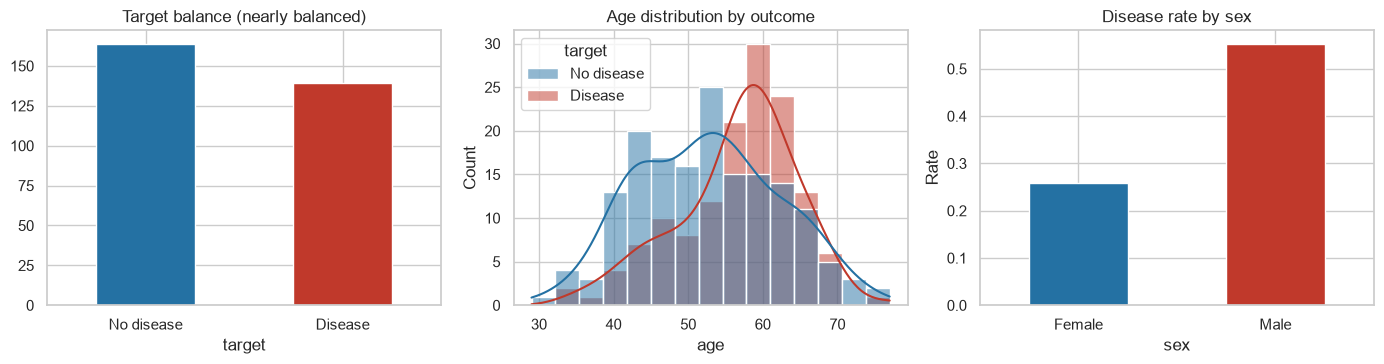

Disease prevalence: 45.9%   |   Male share: 68.0%


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
df['target'].map({0:'No disease',1:'Disease'}).value_counts().plot.bar(ax=ax[0], color=['#2471a3','#c0392b'], rot=0)
ax[0].set_title('Target balance (nearly balanced)')

sns.histplot(data=df, x='age', hue=df['target'].map({0:'No disease',1:'Disease'}), kde=True, bins=15, ax=ax[1], palette=['#2471a3','#c0392b'])
ax[1].set_title('Age distribution by outcome')

rate = df.groupby('sex')['target'].mean().rename({0:'Female',1:'Male'})
rate.plot.bar(ax=ax[2], color=['#2471a3','#c0392b'], rot=0); ax[2].set_title('Disease rate by sex'); ax[2].set_ylabel('Rate')

plt.tight_layout(); plt.show()

print(f"Disease prevalence: {df.target.mean():.1%}   |   Male share: {df.sex.mean():.1%}")

## 3. Numeric features by disease status

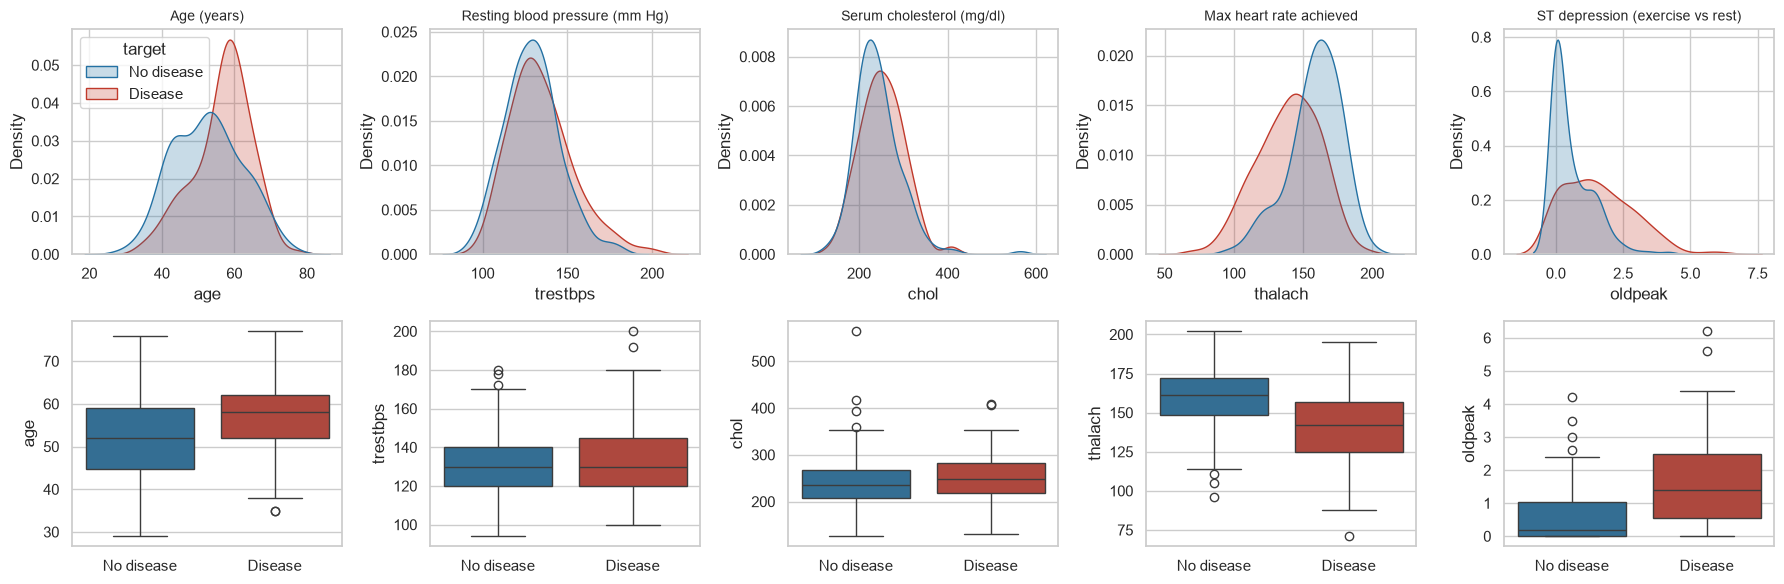

In [5]:
num_cols = ['age','trestbps','chol','thalach','oldpeak']
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
hue = df['target'].map({0:'No disease',1:'Disease'})
for i, c in enumerate(num_cols):
    sns.kdeplot(data=df, x=c, hue=hue, fill=True, common_norm=False, ax=axes[0,i], palette=['#2471a3','#c0392b'], legend=(i==0))
    sns.boxplot(data=df, x=hue, y=c, ax=axes[1,i], palette=['#2471a3','#c0392b'])
    axes[0,i].set_title(LABELS[c], fontsize=10); axes[1,i].set_xlabel('')
plt.tight_layout(); plt.show()

**Observations:** patients with disease tend to have *lower* maximum heart rate (`thalach`) and *higher* ST depression (`oldpeak`); cholesterol and resting BP overlap heavily. `chol` has a few extreme values (max 564) worth noting but they're plausible clinically, so I keep them.

## 4. Categorical features: disease rate by category

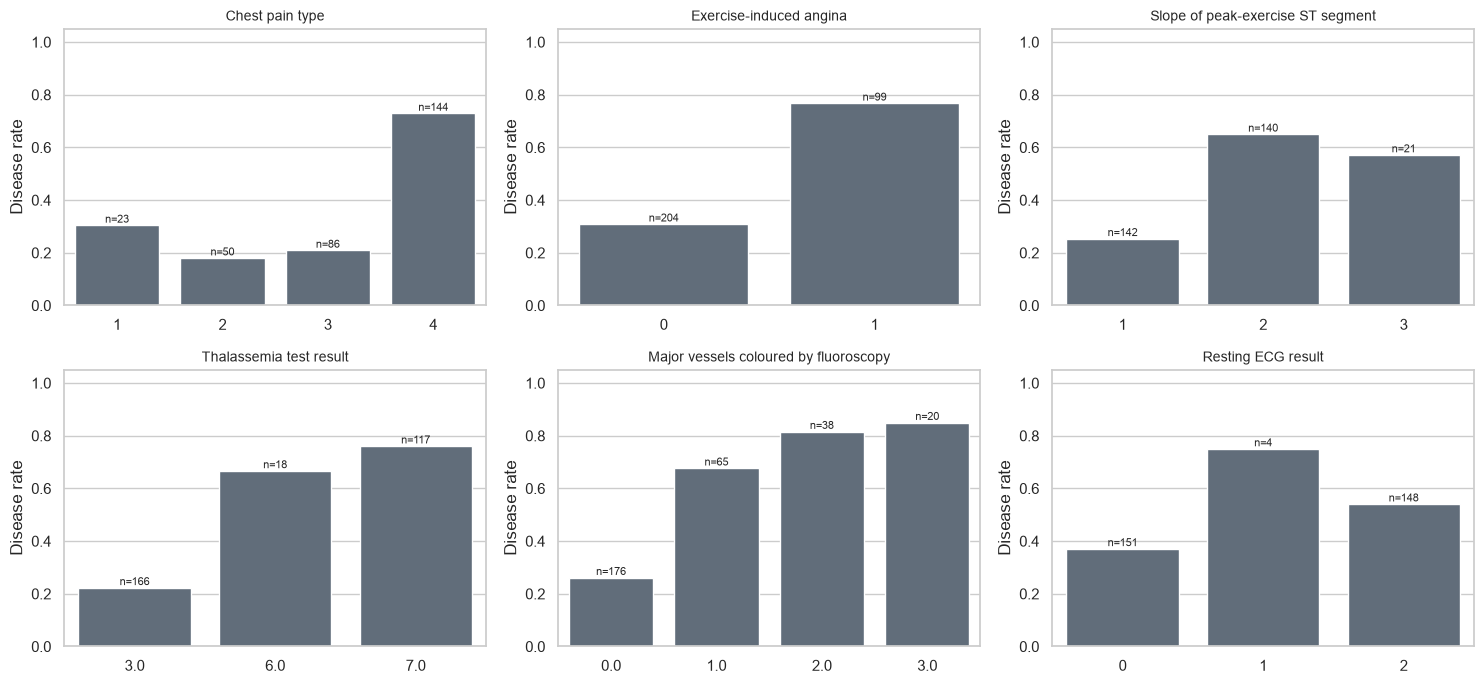

In [6]:
cats = ['cp','exang','slope','thal','ca','restecg']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), cats):
    r = df.groupby(c)['target'].agg(['mean','count'])
    sns.barplot(x=r.index.astype(str), y=r['mean'], ax=ax, color='#5d6d7e')
    for j,(m,n) in enumerate(zip(r['mean'], r['count'])): ax.text(j, m+0.01, f'n={n}', ha='center', fontsize=8)
    ax.set_title(LABELS[c], fontsize=10); ax.set_ylim(0,1.05); ax.set_ylabel('Disease rate'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Observations:** asymptomatic chest pain (`cp = 4`, 73% disease rate vs 18-30% for other types), exercise-induced angina (77% vs 31%), reversible-defect thalassemia (`thal = 7`, 76% vs 22% for normal) and more coloured vessels (`ca`) all coincide with markedly higher disease rates. Atypical chest pain types (1-3) are associated with much *lower* rates, a counter-intuitive but well-known pattern in this dataset.

## 5. Correlations

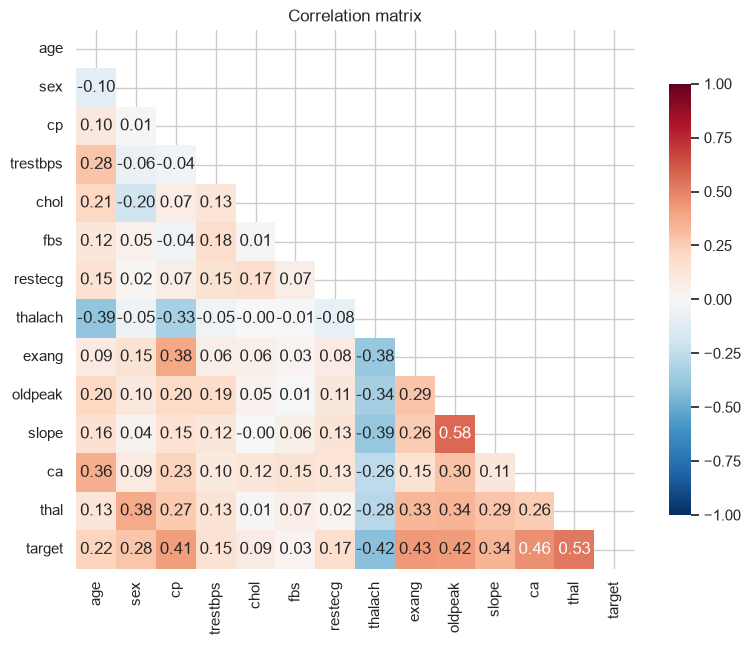

,corr with target
thal,0.53
ca,0.46
exang,0.43
oldpeak,0.42
thalach,-0.42
cp,0.41
slope,0.34
sex,0.28
age,0.22
restecg,0.17


In [7]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, cbar_kws={'shrink':.8})
plt.title('Correlation matrix'); plt.show()
display(corr['target'].drop('target').sort_values(key=abs, ascending=False).round(2).to_frame('corr with target'))

## 6. Statistical tests

In [8]:
from scipy import stats
rows = []
for c in ['age','trestbps','chol','thalach','oldpeak']:
    a, b = df.loc[df.target==1, c].dropna(), df.loc[df.target==0, c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    rows.append({'feature': c, 'test': 'Mann-Whitney U', 'median_disease': a.median(), 'median_healthy': b.median(), 'p_value': p})
for c in ['sex','cp','fbs','restecg','exang','slope','thal','ca']:
    t = pd.crosstab(df[c], df['target']); chi2, p, *_ = stats.chi2_contingency(t)
    rows.append({'feature': c, 'test': 'Chi-square', 'median_disease': np.nan, 'median_healthy': np.nan, 'p_value': p})
tests = pd.DataFrame(rows).sort_values('p_value')
tests['significant (p<0.05, Bonferroni)'] = tests['p_value'] < 0.05/len(tests)
display(tests.round(5))

,feature,test,median_disease,median_healthy,p_value,"significant (p<0.05, Bonferroni)"
11,thal,Chi-square,NaN,NaN,0.00000,True
6,cp,Chi-square,NaN,NaN,0.00000,True
12,ca,Chi-square,NaN,NaN,0.00000,True
9,exang,Chi-square,NaN,NaN,0.00000,True
3,thalach,Mann-Whitney U,142.0,161.0,0.00000,True
4,oldpeak,Mann-Whitney U,1.4,0.2,0.00000,True
10,slope,Chi-square,NaN,NaN,0.00000,True
5,sex,Chi-square,NaN,NaN,0.00000,True
0,age,Mann-Whitney U,58.0,52.0,0.00004,True
8,restecg,Chi-square,NaN,NaN,0.00657,False


Nine of the 13 features (`thal`, `cp`, `ca`, `exang`, `thalach`, `oldpeak`, `slope`, `sex`, `age`) remain significant after Bonferroni correction. `restecg`, `trestbps` and `chol` are only nominally significant (p < 0.05 before correction) and `fbs` shows no association at all.

## 7. Feature engineering ideas
Heart-rate reserve (`thalach / (220 − age)`) normalises max heart rate for age.

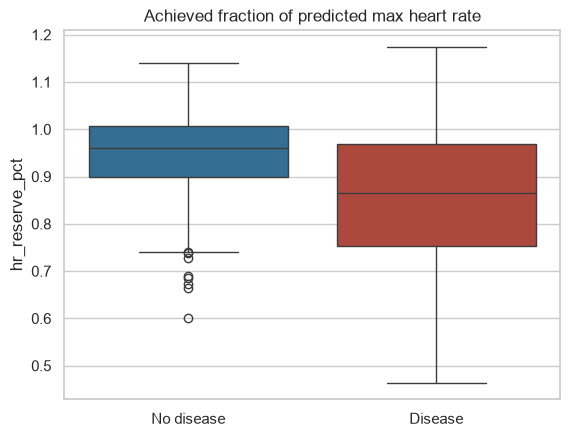

           mean  count
age_group             
<45        0.25     55
45-54      0.34     88
55-64      0.63    119
65+        0.49     41


In [9]:
fe = add_engineered_features(df)
sns.boxplot(data=fe, x=fe['target'].map({0:'No disease',1:'Disease'}), y='hr_reserve_pct', palette=['#2471a3','#c0392b'])
plt.title('Achieved fraction of predicted max heart rate'); plt.xlabel(''); plt.show()
print(fe.groupby('age_group', observed=True)['target'].agg(['mean','count']).round(2))

## Key takeaways
1. Clean, nearly balanced dataset; only 6 missing values.
2. Strongest signals: vessels coloured (`ca`), chest-pain type, thal result, exercise angina, ST depression, max heart rate.
3. Weak signals: cholesterol, fasting blood sugar, resting ECG.
4. Sample is small and male-dominated (68%) — evaluation must use repeated cross-validation and subgroup checks.